# Large-Scale Training: FNN and GPR on 10^5+ FFT-Priced Options

Notebooks 02/03 trained the FNN on 35,000 rows and the exact GPR on at most
10,000 rows. Here **both models are trained on 105,000 rows** (a 150,000-row
FFT dataset split 70/15/15) and compared on:

- a held-out test split of 22,500 rows, and
- the **same 1,000-option shared test set as `03_comparison.ipynb`** (same
  seed), so results line up directly with the smaller models there.

**Why the GPR here is a *sparse* GP.** Exact GPR needs the full `n x n`
kernel matrix: at n = 105,000 that is 105,000^2 x 8 bytes = **~88 GB** of
memory and an `O(n^3)` Cholesky - impossible on this machine (8 GB RAM).
The standard way to scale GPs is a **Sparse Variational Gaussian Process
(SVGP, Hensman et al. 2013)**, implemented with GPyTorch: the posterior is
summarised by `M = 1024` learned *inducing points*, and the model
is trained with mini-batches on the variational ELBO, so cost per step is
`O(batch x M^2 + M^3)` and **every one of the 105,000 points is used**. It
keeps the same kernel family as before (constant x ARD-RBF + Gaussian noise)
and still gives a predictive standard deviation.

In [1]:
from __future__ import annotations

import math
import time
import warnings
from pathlib import Path

import gpytorch
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 20261116
np.random.seed(SEED)
torch.manual_seed(SEED)

FFT_N = 16384
FFT_ETA = 0.25
FFT_ALPHA = 1.5

DATA_DIR = Path("data")
MODELS_DIR = Path("models")
DATA_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

FEATURE_NAMES = ["spot", "strike", "rate", "sigma", "tau"]
COLORS = {"FNN": "tab:blue", "GPR": "tab:purple"}
device = torch.device("cpu")


/Users/mayankbansal/Downloads/BTP/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Pricing functions (identical to notebooks 01-03)

In [2]:
def norm_cdf(x: float) -> float:
    return 0.5 * math.erfc(-x / math.sqrt(2.0))


def bsm_call(spot: float, strike: float, rate: float, sigma: float, tau: float) -> float:
    """European call price, continuously compounded rate, time-to-maturity tau."""
    if spot <= 0 or strike <= 0 or sigma < 0 or tau < 0:
        raise ValueError("spot and strike must be positive; sigma and tau nonnegative")
    if tau == 0:
        return max(spot - strike, 0.0)
    if sigma == 0:
        return max(spot - strike * math.exp(-rate * tau), 0.0)
    vol_time = sigma * math.sqrt(tau)
    d1 = (math.log(spot / strike) + (rate + 0.5 * sigma * sigma) * tau) / vol_time
    d2 = d1 - vol_time
    return spot * norm_cdf(d1) - strike * math.exp(-rate * tau) * norm_cdf(d2)


def mc_call(spot: float, strike: float, rate: float, sigma: float, tau: float,
            normals: np.ndarray) -> float:
    """One-step exact GBM Monte Carlo estimator using caller-supplied N(0,1) draws."""
    if tau == 0:
        return max(spot - strike, 0.0)
    if sigma == 0:
        return max(spot - strike * math.exp(-rate * tau), 0.0)
    terminal = spot * np.exp((rate - 0.5 * sigma * sigma) * tau
                             + sigma * math.sqrt(tau) * normals)
    return math.exp(-rate * tau) * float(np.maximum(terminal - strike, 0.0).mean())


def carr_madan_call(spot: float, strike: float, rate: float, sigma: float,
                    tau: float, n: int = FFT_N, eta: float = FFT_ETA,
                    alpha: float = FFT_ALPHA) -> float:
    """Carr-Madan FFT inversion for a Black-Scholes European call."""
    if spot <= 0 or strike <= 0 or sigma < 0 or tau < 0:
        raise ValueError("spot and strike must be positive; sigma and tau nonnegative")
    if tau == 0 or sigma == 0:
        return bsm_call(spot, strike, rate, sigma, tau)
    if n < 16 or n & (n - 1):
        raise ValueError("FFT size n must be a power of two >= 16")
    if eta <= 0 or alpha <= 0:
        raise ValueError("eta and alpha must be positive")

    j = np.arange(n)
    u = eta * j
    log_forward = math.log(spot) + (rate - 0.5 * sigma * sigma) * tau
    z = u - 1j * (alpha + 1.0)
    phi = np.exp(1j * z * log_forward - 0.5 * sigma * sigma * tau * z * z)
    denominator = alpha * alpha + alpha - u * u + 1j * (2.0 * alpha + 1.0) * u
    psi = math.exp(-rate * tau) * phi / denominator

    weights = np.ones(n)
    weights[1::2] = 4.0
    weights[2:-1:2] = 2.0
    weights /= 3.0
    weights[0] = 1.0 / 3.0
    weights[-1] = 1.0 / 3.0
    b = math.pi / eta
    integrand = np.exp(1j * b * u) * psi * eta * weights
    fft_values = np.fft.fft(integrand)
    dk = 2.0 * math.pi / (n * eta)
    log_strike_grid = -b + dk * np.arange(n)
    calls = np.exp(-alpha * log_strike_grid) * fft_values.real / math.pi
    target = math.log(strike)
    if target < log_strike_grid[0] or target > log_strike_grid[-1]:
        uu = u
        direct_integrand = np.exp(-1j * uu * target) * psi
        direct_integrand[0] *= 0.5
        price = math.exp(-alpha * target) * eta * float(direct_integrand.real.sum()) / math.pi
    else:
        price = float(np.interp(target, log_strike_grid, calls))
    return max(price, 0.0)


def make_dataset(count: int, seed: int) -> list[dict[str, float]]:
    """Generate valid parameter sets; rates may be negative, all other inputs positive."""
    rng = np.random.default_rng(seed)
    spots = rng.uniform(50.0, 200.0, count)
    moneyness = rng.uniform(0.70, 1.30, count)
    rates = rng.uniform(-0.02, 0.10, count)
    sigmas = rng.uniform(0.05, 0.80, count)
    taus = rng.uniform(0.05, 3.0, count)
    return [dict(spot=float(s), strike=float(s * m), rate=float(r),
                 sigma=float(v), tau=float(t))
            for s, m, r, v, t in zip(spots, moneyness, rates, sigmas, taus)]


def error_summary(true: np.ndarray, pred: np.ndarray, floor: float = 0.01) -> dict[str, float]:
    """Errors vs ground truth. Relative error denominator floored at $0.01 (see notebook 02)."""
    abs_err = np.abs(pred - true)
    return {
        "mean_abs_error": float(abs_err.mean()),
        "max_abs_error": float(abs_err.max()),
        "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        "mean_rel_error": float((abs_err / np.maximum(true, floor)).mean()),
        "r2": float(r2_score(true, pred)),
    }


## 1. Generate a 150,000-row FFT dataset

Same sampling ranges as before (`make_dataset`), new seed (`SEED + 150`) so
it is a fresh draw. Each row is priced with Carr-Madan FFT (the training
label, as in notebook 02); the BSM price is stored too for checking.
Pricing takes a couple of minutes, so the result is cached to
`data/fft_dataset_150k.csv` and reused on re-runs.

In [3]:
N_TOTAL = 150_000
DATASET_PATH = DATA_DIR / "fft_dataset_150k.csv"

if DATASET_PATH.exists():
    big_df = pd.read_csv(DATASET_PATH)
    print(f"Loaded cached dataset: {len(big_df):,} rows")
else:
    options = make_dataset(N_TOTAL, SEED + 150)
    t0 = time.perf_counter()
    fft_prices = np.empty(N_TOTAL)
    for i, p in enumerate(options):
        fft_prices[i] = carr_madan_call(**p)
        if (i + 1) % 25_000 == 0:
            print(f"  priced {i + 1:,} / {N_TOTAL:,}  ({time.perf_counter() - t0:.0f}s)")
    big_df = pd.DataFrame(options)
    big_df["fft_price"] = fft_prices
    big_df["bsm_price"] = [bsm_call(**p) for p in options]
    big_df.to_csv(DATASET_PATH, index=False)
    print(f"Generated and priced {N_TOTAL:,} options in {time.perf_counter() - t0:.0f}s")

print(f"max |FFT - BSM| over the whole dataset: {np.abs(big_df.fft_price - big_df.bsm_price).max():.2e}")


  priced 25,000 / 150,000  (20s)


  priced 50,000 / 150,000  (39s)


  priced 75,000 / 150,000  (59s)


  priced 100,000 / 150,000  (79s)


  priced 125,000 / 150,000  (98s)


  priced 150,000 / 150,000  (118s)


Generated and priced 150,000 options in 119s
max |FFT - BSM| over the whole dataset: 9.61e-04


## 2. Train / validation / test split (70 / 15 / 15) and data statistics

In [4]:
idx = np.arange(len(big_df))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=SEED)

X_big = big_df[FEATURE_NAMES].to_numpy(dtype=np.float64)
y_big = big_df["fft_price"].to_numpy(dtype=np.float64)
X_train, y_train = X_big[idx_train], y_big[idx_train]
X_val, y_val = X_big[idx_val], y_big[idx_val]
X_test, y_test = X_big[idx_test], y_big[idx_test]
y_test_bsm = big_df["bsm_price"].to_numpy()[idx_test]

stats = []
for name, ii in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]:
    d = big_df.iloc[ii]
    m = d.strike / d.spot
    stats.append({"split": name, "rows": len(d),
                  "price_mean": d.fft_price.mean(), "price_std": d.fft_price.std(),
                  "price_median": d.fft_price.median(), "price_max": d.fft_price.max(),
                  "sigma_mean": d.sigma.mean(), "tau_mean": d.tau.mean(), "rate_mean": d.rate.mean(),
                  "ITM_%": (m < 0.97).mean() * 100, "ATM_%": ((m >= 0.97) & (m <= 1.03)).mean() * 100,
                  "OTM_%": (m > 1.03).mean() * 100, "price_below_1c": int((d.fft_price < 0.01).sum())})
split_stats = pd.DataFrame(stats).set_index("split")
split_stats.to_csv(DATA_DIR / "large_scale_split_stats.csv")
split_stats.round(3)


,rows,price_mean,price_std,price_median,price_max,sigma_mean,tau_mean,rate_mean,ITM_%,ATM_%,OTM_%,price_below_1c
split,,,,,,,,,,,,
train,105000,29.599,21.000,25.905,125.989,0.426,1.527,0.04,45.040,10.164,44.796,861
validation,22500,29.521,20.912,26.046,122.361,0.425,1.526,0.04,44.800,9.716,45.484,204
test,22500,29.628,21.030,26.054,122.054,0.424,1.527,0.04,45.329,10.093,44.578,195


In [5]:
sx = StandardScaler().fit(X_train)
sy = StandardScaler().fit(y_train.reshape(-1, 1))


def tens(a: np.ndarray) -> torch.Tensor:
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))


Xtr_t, Xval_t, Xte_t = (tens(sx.transform(a)) for a in (X_train, X_val, X_test))
ytr_t = tens(sy.transform(y_train.reshape(-1, 1)).ravel())
yval_t = tens(sy.transform(y_val.reshape(-1, 1)).ravel())


def unscale(pred_scaled: np.ndarray) -> np.ndarray:
    return sy.inverse_transform(np.asarray(pred_scaled).reshape(-1, 1)).ravel()


def error_summary(true: np.ndarray, pred: np.ndarray, floor: float = 0.01) -> dict[str, float]:
    abs_err = np.abs(pred - true)
    return {"mean_abs_error": float(abs_err.mean()), "max_abs_error": float(abs_err.max()),
            "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
            "mean_rel_error": float((abs_err / np.maximum(true, floor)).mean()),
            "r2": float(r2_score(true, pred)),
            "within_0.10": float((abs_err <= 0.10).mean()), "within_0.25": float((abs_err <= 0.25).mean())}


## 3. FNN on 105,000 rows

Same architecture as notebook 02 (5 -> 128 -> 128 -> 64 -> 32 -> 1, ReLU).
Adam (lr 1e-3) with cosine decay, batch 1,024, 200 epochs; the weights
with the best validation loss are kept.

In [6]:
class OptionPricerMLP(nn.Module):
    def __init__(self, n_features: int = 5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


FNN_EPOCHS = 200
torch.manual_seed(SEED)
fnn = OptionPricerMLP(len(FEATURE_NAMES))
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr_t, ytr_t.unsqueeze(1)),
                                     batch_size=1024, shuffle=True)
opt = torch.optim.Adam(fnn.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FNN_EPOCHS * len(loader))
loss_fn = nn.MSELoss()

fnn_hist = {"train": [], "val": []}
best_val, best_state = float("inf"), None
t0 = time.perf_counter()
for epoch in range(1, FNN_EPOCHS + 1):
    fnn.train()
    running = 0.0
    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(fnn(xb), yb)
        loss.backward()
        opt.step(); sched.step()
        running += loss.item() * xb.size(0)
    fnn.eval()
    with torch.no_grad():
        val_loss = loss_fn(fnn(Xval_t), yval_t.unsqueeze(1)).item()
    fnn_hist["train"].append(running / len(Xtr_t)); fnn_hist["val"].append(val_loss)
    if val_loss < best_val:
        best_val, best_state = val_loss, {k: v.clone() for k, v in fnn.state_dict().items()}
    if epoch == 1 or epoch % 25 == 0:
        print(f"epoch {epoch:4d}  train={fnn_hist['train'][-1]:.2e}  val={val_loss:.2e}  ({time.perf_counter() - t0:.0f}s)")
fnn_fit_seconds = time.perf_counter() - t0
fnn.load_state_dict(best_state); fnn.eval()
print(f"FNN trained on {len(X_train):,} rows in {fnn_fit_seconds:.0f}s (best val loss {best_val:.2e})")


epoch    1  train=1.53e-01  val=7.69e-03  (1s)


epoch   25  train=3.11e-04  val=4.18e-04  (12s)


epoch   50  train=1.70e-04  val=1.44e-04  (24s)


epoch   75  train=9.14e-05  val=7.16e-05  (36s)


epoch  100  train=6.38e-05  val=5.53e-05  (47s)


epoch  125  train=4.12e-05  val=3.98e-05  (59s)


epoch  150  train=3.37e-05  val=3.59e-05  (71s)


epoch  175  train=2.96e-05  val=3.32e-05  (83s)


epoch  200  train=2.80e-05  val=3.18e-05  (94s)
FNN trained on 105,000 rows in 94s (best val loss 3.18e-05)


## 4. Sparse GPR (SVGP) on 105,000 rows

- `M = 1024` inducing points, initialised at random training
  inputs and then **learned**.
- Kernel: `Scale x RBF(5 ARD length scales)`, constant mean, Gaussian
  likelihood (noise learned) - the same family as the exact GPR before.
- Mini-batch (1,024) Adam on the variational ELBO, lr 0.01 with cosine
  decay, 30 epochs over all 105,000 points. Validation MAE tracked.

In [7]:
class SVGPModel(gpytorch.models.ApproximateGP):
    def __init__(self, inducing_points: torch.Tensor):
        var_dist = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
        var_strat = gpytorch.variational.VariationalStrategy(
            self, inducing_points, var_dist, learn_inducing_locations=True)
        super().__init__(var_strat)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.RBFKernel(ard_num_dims=len(FEATURE_NAMES)))

    def forward(self, x):
        return gpytorch.distributions.MultivariateNormal(self.mean_module(x), self.covar_module(x))


def svgp_predict(model, likelihood, X_scaled: torch.Tensor, return_std: bool = False,
                 batch: int = 8192):
    model.eval(); likelihood.eval()
    mus, sds = [], []
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        for i in range(0, len(X_scaled), batch):
            out = likelihood(model(X_scaled[i:i + batch]))
            mus.append(out.mean.numpy())
            if return_std:
                sds.append(out.stddev.numpy())
    mu = unscale(np.concatenate(mus))
    if return_std:
        return mu, np.concatenate(sds) * sy.scale_[0]
    return mu


SVGP_INDUCING, SVGP_EPOCHS = 1024, 30
torch.manual_seed(SEED)
Z0 = Xtr_t[torch.randperm(len(Xtr_t))[:SVGP_INDUCING]].clone()
svgp = SVGPModel(Z0)
svgp_lik = gpytorch.likelihoods.GaussianLikelihood()
gp_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr_t, ytr_t),
                                        batch_size=1024, shuffle=True)
gp_opt = torch.optim.Adam(list(svgp.parameters()) + list(svgp_lik.parameters()), lr=0.01)
gp_sched = torch.optim.lr_scheduler.CosineAnnealingLR(gp_opt, T_max=SVGP_EPOCHS * len(gp_loader))
elbo = gpytorch.mlls.VariationalELBO(svgp_lik, svgp, num_data=len(ytr_t))

gp_hist = {"neg_elbo": [], "val_mae": []}
t0 = time.perf_counter()
for epoch in range(1, SVGP_EPOCHS + 1):
    svgp.train(); svgp_lik.train()
    running = 0.0
    for xb, yb in gp_loader:
        gp_opt.zero_grad()
        loss = -elbo(svgp(xb), yb)
        loss.backward()
        gp_opt.step(); gp_sched.step()
        running += loss.item() * xb.size(0)
    gp_hist["neg_elbo"].append(running / len(Xtr_t))
    gp_hist["val_mae"].append(float(np.abs(svgp_predict(svgp, svgp_lik, Xval_t) - y_val).mean()))
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:3d}  -ELBO={gp_hist['neg_elbo'][-1]:.4f}  val MAE={gp_hist['val_mae'][-1]:.4f}  "
              f"({time.perf_counter() - t0:.0f}s)")
gpr_fit_seconds = time.perf_counter() - t0
print(f"SVGP trained on {len(X_train):,} rows in {gpr_fit_seconds:.0f}s")
print("Learned ARD length scales (standardized inputs):",
      dict(zip(FEATURE_NAMES, svgp.covar_module.base_kernel.lengthscale.detach().numpy().ravel().round(3))))


epoch   1  -ELBO=0.9424  val MAE=1.0935  (13s)


epoch   5  -ELBO=-1.3385  val MAE=0.3810  (66s)


epoch  10  -ELBO=-2.3746  val MAE=0.2257  (132s)


epoch  15  -ELBO=-2.5523  val MAE=0.1854  (199s)


epoch  20  -ELBO=-2.6271  val MAE=0.1525  (266s)


epoch  25  -ELBO=-2.6649  val MAE=0.1362  (333s)


epoch  30  -ELBO=-2.6792  val MAE=0.1306  (402s)
SVGP trained on 105,000 rows in 402s
Learned ARD length scales (standardized inputs): {'spot': np.float32(1.587), 'strike': np.float32(1.377), 'rate': np.float32(4.207), 'sigma': np.float32(2.18), 'tau': np.float32(2.097)}


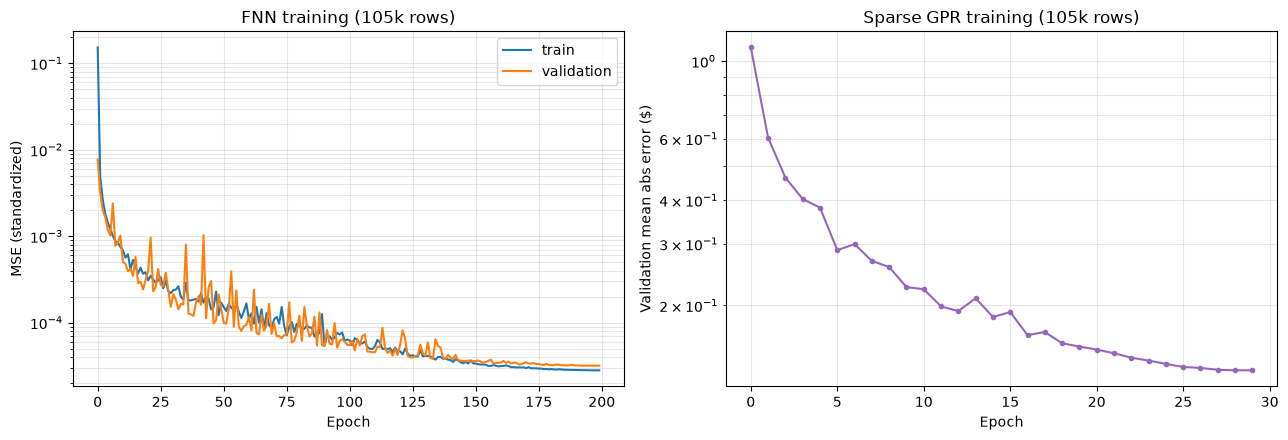

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(fnn_hist["train"], label="train"); ax1.plot(fnn_hist["val"], label="validation")
ax1.set_yscale("log"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("MSE (standardized)")
ax1.set_title("FNN training (105k rows)"); ax1.legend(); ax1.grid(True, which="both", alpha=0.3)
ax2.plot(gp_hist["val_mae"], color=COLORS["GPR"], marker="o", ms=3)
ax2.set_yscale("log"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Validation mean abs error ($)")
ax2.set_title("Sparse GPR training (105k rows)"); ax2.grid(True, which="both", alpha=0.3)
fig.tight_layout(); fig.savefig(DATA_DIR / "large_scale_training_curves.png", dpi=150); plt.show()


## 5. Evaluation

### 5a. Held-out test split (22,500 rows), errors vs FFT labels and vs BSM

In [9]:
t0 = time.perf_counter()
with torch.no_grad():
    fnn_test = unscale(fnn(Xte_t).numpy().ravel())
fnn_pred_us = (time.perf_counter() - t0) / len(X_test) * 1e6

t0 = time.perf_counter()
gpr_test, gpr_test_sd = svgp_predict(svgp, svgp_lik, Xte_t, return_std=True)
t0b = time.perf_counter(); _ = svgp_predict(svgp, svgp_lik, Xte_t); gpr_pred_us = (time.perf_counter() - t0b) / len(X_test) * 1e6

test_rows = []
for name, pred in [("FNN", fnn_test), ("GPR", gpr_test)]:
    test_rows.append({"model": name, "vs": "FFT label", **error_summary(y_test, pred)})
    test_rows.append({"model": name, "vs": "BSM", **error_summary(y_test_bsm, pred)})
test_df = pd.DataFrame(test_rows)
test_df.to_csv(DATA_DIR / "large_scale_test_metrics.csv", index=False)
coverage = float((np.abs(gpr_test - y_test) <= 2 * gpr_test_sd).mean())
print(f"Sparse GPR: {coverage:.1%} of test labels within +/-2 sigma (ideal ~95%)")
test_df.style.format({c: "{:.4f}" for c in ["mean_abs_error", "max_abs_error", "rmse"]} |
                     {"mean_rel_error": "{:.2%}", "r2": "{:.6f}", "within_0.10": "{:.1%}", "within_0.25": "{:.1%}"})


Sparse GPR: 98.7% of test labels within +/-2 sigma (ideal ~95%)


,model,vs,mean_abs_error,max_abs_error,rmse,mean_rel_error,r2,within_0.10,within_0.25
0,FNN,FFT label,0.0912,1.1887,0.1190,13.53%,0.999968,63.5%,96.2%
1,FNN,BSM,0.0912,1.1887,0.1190,13.53%,0.999968,63.5%,96.2%
2,GPR,FFT label,0.1320,3.1151,0.2279,74.12%,0.999883,60.3%,86.9%
3,GPR,BSM,0.1320,3.1151,0.2279,74.13%,0.999883,60.3%,86.9%


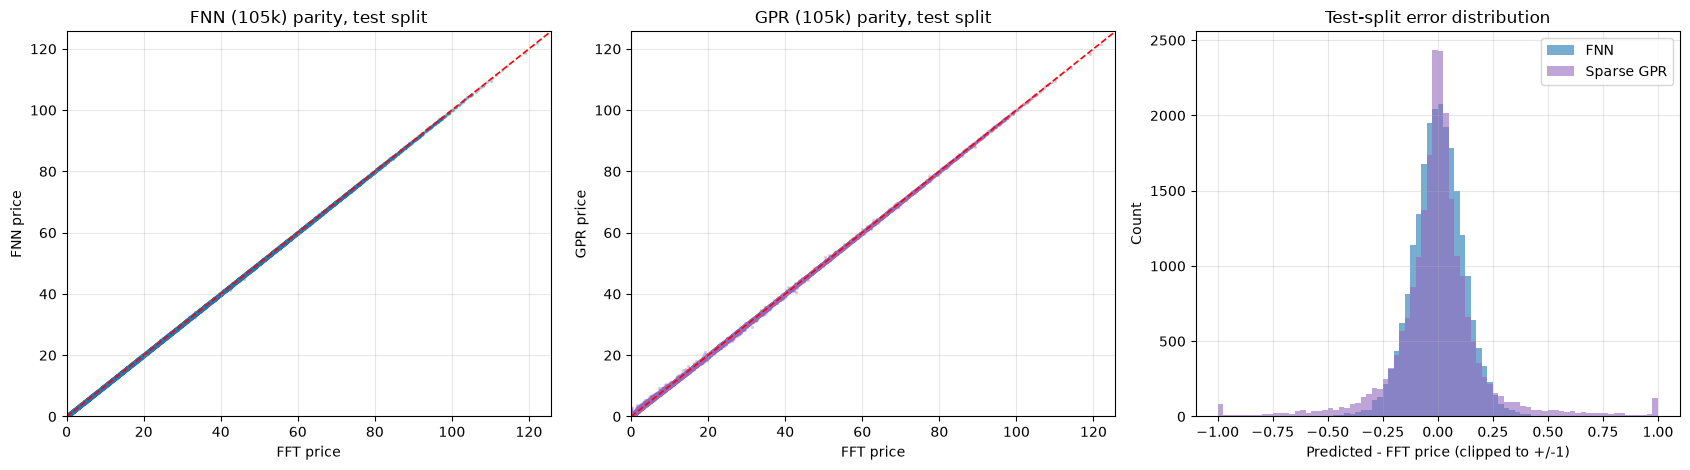

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
lim = [0, y_test.max() * 1.03]
for ax, (name, pred) in zip(axes[:2], [("FNN", fnn_test), ("GPR", gpr_test)]):
    ax.scatter(y_test, pred, s=2, alpha=0.25, color=COLORS[name])
    ax.plot(lim, lim, "r--", lw=1.2)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("FFT price"); ax.set_ylabel(f"{name} price")
    ax.set_title(f"{name} (105k) parity, test split"); ax.grid(True, alpha=0.3)
bins = np.linspace(-1, 1, 81)
axes[2].hist(np.clip(fnn_test - y_test, -1, 1), bins=bins, alpha=0.6, color=COLORS["FNN"], label="FNN")
axes[2].hist(np.clip(gpr_test - y_test, -1, 1), bins=bins, alpha=0.6, color=COLORS["GPR"], label="Sparse GPR")
axes[2].set_xlabel("Predicted - FFT price (clipped to +/-1)"); axes[2].set_ylabel("Count")
axes[2].set_title("Test-split error distribution"); axes[2].legend(); axes[2].grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(DATA_DIR / "large_scale_test_parity.png", dpi=150); plt.show()


### 5b. Same 1,000-option shared test set as notebook 03 (errors vs BSM)

Rebuilt with the identical seed (`SEED + 2026`), so these numbers are
directly comparable to the small-data models measured in notebook 03
(`data/gpr_vs_fnn_bsm.csv`).

In [11]:
shared = pd.DataFrame(make_dataset(1000, SEED + 2026))[FEATURE_NAMES]
X_sh = shared.to_numpy(dtype=np.float64)
true_sh = np.array([bsm_call(*r) for r in X_sh])
Xsh_t = tens(sx.transform(X_sh))
with torch.no_grad():
    fnn_sh = unscale(fnn(Xsh_t).numpy().ravel())
gpr_sh = svgp_predict(svgp, svgp_lik, Xsh_t)

fnn_bytes = sum(p.numel() for p in fnn.parameters()) * 4
gpr_bytes = sum(p.numel() for p in list(svgp.parameters()) + list(svgp_lik.parameters())) * 4

rows = [{"model": "FNN", "train_size": len(X_train), "label_source": "FFT", "approach": "MLP",
         **error_summary(true_sh, fnn_sh), "fit_seconds": fnn_fit_seconds,
         "predict_us_per_option": fnn_pred_us, "model_memory_MB": fnn_bytes / 1e6},
        {"model": "GPR", "train_size": len(X_train), "label_source": "FFT",
         "approach": f"sparse SVGP (M={SVGP_INDUCING})",
         **error_summary(true_sh, gpr_sh), "fit_seconds": gpr_fit_seconds,
         "predict_us_per_option": gpr_pred_us, "model_memory_MB": gpr_bytes / 1e6}]
large_df = pd.DataFrame(rows)

prev = pd.read_csv(DATA_DIR / "gpr_vs_fnn_bsm.csv")
prev["approach"] = np.where(prev["model"].str.startswith("GPR"), "exact GPR", "MLP")
prev["model"] = prev["model"].str.replace(" (nb 02)", "", regex=False)
combined = pd.concat([prev, large_df], ignore_index=True)[
    ["model", "approach", "train_size", "label_source", "mean_abs_error", "max_abs_error", "rmse",
     "r2", "within_0.10", "fit_seconds", "predict_us_per_option", "model_memory_MB"]]
combined = combined.sort_values(["model", "train_size"]).reset_index(drop=True)
combined.to_csv(DATA_DIR / "large_scale_vs_small_models.csv", index=False)
combined.style.format({"mean_abs_error": "{:.4f}", "max_abs_error": "{:.4f}", "rmse": "{:.4f}",
                       "r2": "{:.6f}", "within_0.10": "{:.1%}", "fit_seconds": "{:.1f}",
                       "predict_us_per_option": "{:.2f}", "model_memory_MB": "{:.2f}"}, na_rep="-")


,model,approach,train_size,label_source,mean_abs_error,max_abs_error,rmse,r2,within_0.10,fit_seconds,predict_us_per_option,model_memory_MB
0,FNN,MLP,2000,BSM,0.2840,3.2415,0.4012,0.999650,-,18.1,0.96,0.11
1,FNN,MLP,5000,BSM,0.1955,2.1173,0.2689,0.999843,-,18.2,0.66,0.11
2,FNN,MLP,10000,BSM,0.1615,2.0270,0.2217,0.999893,-,18.2,0.94,0.11
3,FNN,MLP,35000,FFT,0.1285,1.1797,0.1720,0.999936,-,-,0.70,0.11
4,FNN,MLP,105000,FFT,0.0938,0.5945,0.1220,0.999968,62.1%,94.4,0.44,0.11
5,GPR,exact GPR,2000,BSM,0.1425,3.5441,0.3129,0.999787,-,0.1,17.02,32.10
6,GPR,exact GPR,5000,BSM,0.0931,2.5657,0.2023,0.999911,-,1.2,43.29,200.24
7,GPR,exact GPR,10000,BSM,0.0713,1.2155,0.1411,0.999957,-,7.9,77.40,800.48
8,GPR,sparse SVGP (M=1024),105000,FFT,0.1340,2.3516,0.2327,0.999882,59.5%,401.7,22.07,4.22


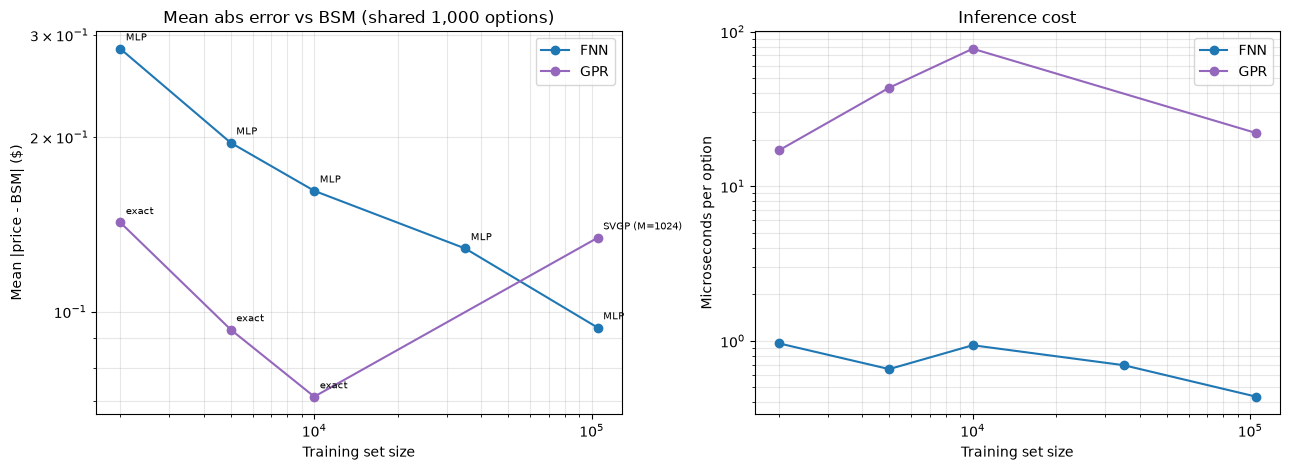

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for name in ["FNN", "GPR"]:
    d = combined[combined["model"] == name].sort_values("train_size")
    ax1.plot(d["train_size"], d["mean_abs_error"], "o-", color=COLORS[name], label=name)
    for _, r in d.iterrows():
        ax1.annotate(r["approach"].replace(" GPR", "").replace("sparse ", ""), (r["train_size"], r["mean_abs_error"]),
                     textcoords="offset points", xytext=(4, 6), fontsize=7)
    ax2.plot(d["train_size"], d["predict_us_per_option"], "o-", color=COLORS[name], label=name)
for ax, t, yl in [(ax1, "Mean abs error vs BSM (shared 1,000 options)", "Mean |price - BSM| ($)"),
                  (ax2, "Inference cost", "Microseconds per option")]:
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Training set size")
    ax.set_ylabel(yl); ax.set_title(t); ax.legend(); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); fig.savefig(DATA_DIR / "large_scale_scaling.png", dpi=150); plt.show()


## 6. Save models and summarise

In [13]:
torch.save(fnn.state_dict(), MODELS_DIR / "fnn_105k.pt")
torch.save({"svgp": svgp.state_dict(), "likelihood": svgp_lik.state_dict()}, MODELS_DIR / "svgp_105k.pt")
joblib.dump(sx, MODELS_DIR / "scaler_X_105k.joblib")
joblib.dump(sy, MODELS_DIR / "scaler_y_105k.joblib")

f, g = large_df.iloc[0], large_df.iloc[1]
print(f"Both models trained on {len(X_train):,} FFT-priced options.")
print(f"Shared 1,000-option set (vs BSM): FNN mean abs err {f.mean_abs_error:.4f} | sparse GPR {g.mean_abs_error:.4f}")
print(f"Training time: FNN {f.fit_seconds:.0f}s | sparse GPR {g.fit_seconds:.0f}s")
print(f"Inference: FNN {f.predict_us_per_option:.2f} us | sparse GPR {g.predict_us_per_option:.2f} us per option")
print(f"Model size: FNN {f.model_memory_MB:.2f} MB | sparse GPR {g.model_memory_MB:.2f} MB "
      f"(exact GPR at this n would need ~{len(X_train) ** 2 * 8 / 1e9:.0f} GB)")
for name in ["FNN", "GPR"]:
    d = combined[combined["model"] == name].sort_values("train_size")
    print(f"{name}: mean abs err {d.mean_abs_error.iloc[0]:.4f} (n={d.train_size.iloc[0]:,}) -> "
          f"{d.mean_abs_error.iloc[-1]:.4f} (n={d.train_size.iloc[-1]:,})")


Both models trained on 105,000 FFT-priced options.
Shared 1,000-option set (vs BSM): FNN mean abs err 0.0938 | sparse GPR 0.1340
Training time: FNN 94s | sparse GPR 402s
Inference: FNN 0.44 us | sparse GPR 22.07 us per option
Model size: FNN 0.11 MB | sparse GPR 4.22 MB (exact GPR at this n would need ~88 GB)
FNN: mean abs err 0.2840 (n=2,000) -> 0.0938 (n=105,000)
GPR: mean abs err 0.1425 (n=2,000) -> 0.1340 (n=105,000)


**Takeaways**

- With 10^5 training rows the FNN keeps improving: more data is the main
  lever for an MLP, and its inference cost and model size don't change.
- Exact GPR cannot be trained at this size (memory ~88 GB); a sparse
  variational GP makes it feasible, using all 105k points through `M`
  inducing points. Its accuracy is then capped by `M` rather than `n`, which
  is the price paid for scalability - compare it with the exact 10k GPR
  in the table above.
- The sparse GP keeps GPR's advantages of a predictive uncertainty and a
  fixed-size model (inference `O(M)` instead of `O(n)` per option).